# K-means clustering of the session features

**Goal:** see if the sessions form 3 natural groups (k = 3, like WT / NPC / EFV), **watch how k-means finds them step by step**, and then **look at the feature values** to understand what makes each cluster different.

### How k-means works (in words)
1. **Start:** put *k* centres somewhere in the feature space.
2. **Assign:** every session goes to its **nearest** centre → this makes *k* clusters.
3. **Update:** move every centre to the **average** of the sessions assigned to it.
4. **Repeat** 2 and 3 until the centres stop moving.

It is **unsupervised**: k-means never sees the group labels (WT / NPC / EFV). At the end we compare its clusters with the real groups.

### Important about the pictures
K-means works in the **full feature space** (all your standardized features at once), which we cannot draw. To *see* it, every step is projected onto **two principal components**, like a shadow on a wall. So two points that look close in the picture may be far apart in the full space: the picture is a guide, the computation uses all the features.

### Why PC1 and PC2?
A flat picture has only 2 axes, so we have to choose 2 directions. PC1 and PC2 are the default because they are the two directions where the sessions differ the most (the largest share of the variance), so they are the "most informative shadow". But they are not the only one: **you can choose any pair** with `PC_X` and `PC_Y` in the settings (e.g. PC1 vs PC3), and section 3 shows a grid with **every pair** of the first PCs at once.

### Feature families
Your features come in 3 families, and you can run the whole notebook on one family at a time with `FEATURE_SET` (results go to a separate folder for each family):

| Family | What it measures | Features |
|---|---|---|
| `ripple` | properties of the ripples themselves (frequency, amplitude, power) | 3 |
| `CSD` | sinks and sources during ripples, per layer (SO, PYR, RAD, SLM) × mean / median / std | 12 |
| `power` | LFP power spectrum: 7 bands (Delta, Theta, Alpha, Slow/Mid/Fast Gamma, Ripple) × 2 layers (PYR, SLM) × 2 brain states (Theta, LIA) × mean / max | ~56 |

`power` is so big that it can be split further with `POWER_LAYER`, `POWER_STATE` and `POWER_STAT`.

**Run the cells in order** (Shift + Enter). Keep this notebook in the same folder as `pca_analysis_new.py`.

## 1. Settings and data

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib import animation
from IPython.display import HTML, display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, kmeans_plusplus
from sklearn.metrics import adjusted_rand_score, silhouette_score

# Same Excel, columns and feature selection as the PCA (pca_analysis_new.py, same folder)
import pca_analysis_new as cfg

# ---------------- SETTINGS ----------------
K = 3                 # number of clusters
INIT = "random"       # "random": k random sessions as starting centres (more movement to watch)
                      # "k-means++": smart start, far-apart centres (what sklearn uses)
SEED = 0              # change it to see another random start
MAX_ITER = 50
PC_X, PC_Y = 1, 2     # which principal components are used for the 2-D pictures
N_PCS_GRID = 4        # the "all pairs" grid shows PC1 ... PC{N_PCS_GRID}
FEATURE_FILTER = None # section 4b: None = all features, or text, e.g. "Theta", "SLM"

# Which FAMILY of features k-means uses (see the table printed in section 1):
FEATURE_SET = "all"   # "all", "ripple", "CSD" or "power"
# Only for FEATURE_SET = "power" (None = keep all):
POWER_LAYER = None    # "PYR" or "SLM"
POWER_STATE = None    # "Theta" (theta periods) or "LIA" (LIA periods)
POWER_STAT = None     # "mean" or "max"

set_name = "_".join(str(v) for v in [FEATURE_SET, POWER_LAYER, POWER_STATE, POWER_STAT]
                    if v is not None and (FEATURE_SET == "power" or v == FEATURE_SET))
OUTPUT_DIR = cfg.RESULTS_DIR / f"kmeans_results{getattr(cfg, 'RUN_TAG', '')}" / set_name
CLUSTER_COLORS = ["#7b3294", "#e66101", "#018571", "#5e3c99", "#b2abd2", "#fdb863"]
CLUSTER_MARKERS = ["o", "s", "^", "D", "v", "P"]
# ------------------------------------------

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams["figure.dpi"] = 110

In [2]:
ids, feats = cfg.load_data(cfg.EXCEL_PATH, cfg.SHEET, cfg.ID_COLS)
groups = ids[cfg.GROUP_COL].astype(str).to_numpy()
animals = ids["animal"].astype(str).to_numpy()
import re
POWER_RE = re.compile(r"^(Delta|Theta|Alpha|SlowGamma|MidGamma|FastGamma|Ripple)_(PYR|SLM)_(Theta|LIA)_(mean|max)$",
                      re.IGNORECASE)

def feature_family(name):
    if POWER_RE.match(name):
        return "power"
    if name.upper().startswith("CSD_"):
        return "CSD"
    if name.lower().startswith("ripple_"):
        return "ripple"
    return "other"

families = pd.Series({f: feature_family(f) for f in feats.columns}, name="family")
print("Feature families in your table:")
for fam, cols in families.groupby(families).groups.items():
    print(f"  {fam:7s} {len(cols):3d} features")

keep = list(feats.columns) if FEATURE_SET == "all" else list(families.index[families == FEATURE_SET])
if FEATURE_SET == "power":
    for part, val in [(1, POWER_LAYER), (2, POWER_STATE), (3, POWER_STAT)]:
        if val is not None:
            keep = [f for f in keep if POWER_RE.match(f).group(part + 1).lower() == val.lower()]
if len(keep) < 2:
    raise ValueError(f"Only {len(keep)} feature(s) selected: check FEATURE_SET / POWER_* settings")
feats = feats[keep]
feature_names = keep
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"\nUsing feature set '{set_name}': {len(keep)} features -> results in {OUTPUT_DIR}")

X = StandardScaler().fit_transform(feats.to_numpy())   # z-scores, same as the PCA
print(f"{X.shape[0]} sessions x {X.shape[1]} features")
print(pd.Series(groups).value_counts().to_dict())

# PCA used ONLY for the pictures (k-means itself uses all the features)
n_pc = min(max(PC_X, PC_Y, N_PCS_GRID), X.shape[1], X.shape[0])
pca = PCA(n_components=n_pc).fit(X)
P_all = pca.transform(X)                     # sessions on PC1 ... PC{n_pc}
var_all = pca.explained_variance_ratio_ * 100
pcs = [PC_X - 1, PC_Y - 1]

def proj(A):
    # Coordinates of any points (sessions or centres) on the chosen pair of PCs
    return pca.transform(np.atleast_2d(A))[:, pcs]

P = P_all[:, pcs]
var2 = var_all[pcs]
xlab, ylab = f"PC{PC_X} ({var2[0]:.0f}%)", f"PC{PC_Y} ({var2[1]:.0f}%)"
pair_name = f"PC{PC_X}-PC{PC_Y}"
print("Variance explained by each PC: " +
      ", ".join(f"PC{i + 1} {v:.0f}%" for i, v in enumerate(var_all)))
print(f"The {pair_name} picture shows {var2.sum():.0f}% of the variance")

[i] Left out (channels / checks / counts): []
[!] Removed 1 row(s) with missing values
Feature families in your table:
  power    13 features
  ripple    2 features

Using feature set 'all': 15 features -> results in D:\Violeta\ANALISIS\RESULTSNatalia\kmeans_results_selected\all
88 sessions x 15 features
{'NPC': 41, 'EFV': 37, 'WT': 10}
Variance explained by each PC: PC1 47%, PC2 17%, PC3 14%, PC4 7%
The PC1-PC2 picture shows 64% of the variance


In [3]:
# Sessions of the "odd subgroup" (if check_odd_subgroup.py was run), to mark them later
odd_file = cfg.RESULTS_DIR / "embedding_results" / "subgroup_check" / "subgroup_check.xlsx"
odd = np.zeros(len(ids), bool)
if odd_file.exists():
    o = pd.read_excel(odd_file, sheet_name="subgroup_sessions")
    odd_keys = set(o["animal"].astype(str) + "|" + o["session"].astype(str))
    odd = (ids["animal"].astype(str) + "|" + ids["session"].astype(str)).isin(odd_keys).to_numpy()
    print(f"Odd subgroup found: {odd.sum()} sessions (they will be circled in black)")
else:
    print("No odd-subgroup file found (fine, it is optional)")

No odd-subgroup file found (fine, it is optional)


## 2. K-means step by step

We write k-means ourselves (it is only a few lines) so that we can **save every step**: the centres, which cluster every session belongs to, and the **inertia**.

**Inertia** = sum of the squared distances from every session to its centre. It measures how "tight" the clusters are, and it can only go down at every step. When it stops going down, k-means has finished (*converged*).

In [4]:
def kmeans_with_history(X, k, init="random", seed=0, max_iter=50):
    rng = np.random.default_rng(seed)
    if init == "random":
        centres = X[rng.choice(len(X), size=k, replace=False)].copy()
    else:
        centres, _ = kmeans_plusplus(X, n_clusters=k, random_state=seed)

    history = []
    for it in range(max_iter):
        # STEP "assign": distance of every session to every centre -> nearest one
        dist2 = ((X[:, None, :] - centres[None, :, :]) ** 2).sum(axis=2)
        labels = dist2.argmin(axis=1)
        inertia = dist2[np.arange(len(X)), labels].sum()
        history.append({"centres": centres.copy(), "labels": labels.copy(), "inertia": inertia})

        # STEP "update": every centre moves to the mean of its sessions
        new_centres = np.array([X[labels == j].mean(axis=0) if np.any(labels == j) else centres[j]
                                for j in range(k)])
        if np.allclose(new_centres, centres):
            break   # centres did not move -> converged
        centres = new_centres
    return history


history = kmeans_with_history(X, K, init=INIT, seed=SEED, max_iter=MAX_ITER)
print(f"Converged after {len(history)} steps")
for i, h in enumerate(history):
    sizes = np.bincount(h["labels"], minlength=K)
    print(f"step {i:2d}: inertia = {h['inertia']:8.1f}   cluster sizes = {sizes.tolist()}")

Converged after 8 steps
step  0: inertia =   1528.4   cluster sizes = [68, 11, 9]
step  1: inertia =   1100.3   cluster sizes = [44, 31, 13]
step  2: inertia =    952.1   cluster sizes = [31, 44, 13]
step  3: inertia =    875.1   cluster sizes = [33, 47, 8]
step  4: inertia =    822.7   cluster sizes = [35, 48, 5]
step  5: inertia =    771.5   cluster sizes = [34, 50, 4]
step  6: inertia =    757.2   cluster sizes = [33, 51, 4]
step  7: inertia =    756.3   cluster sizes = [33, 51, 4]


### 2a. The steps as a grid of pictures
Each panel is one step. Sessions are colored by the cluster they belong to **at that step**; the big **X** marks are the centres, and the thin line behind each X is the path it has travelled so far.

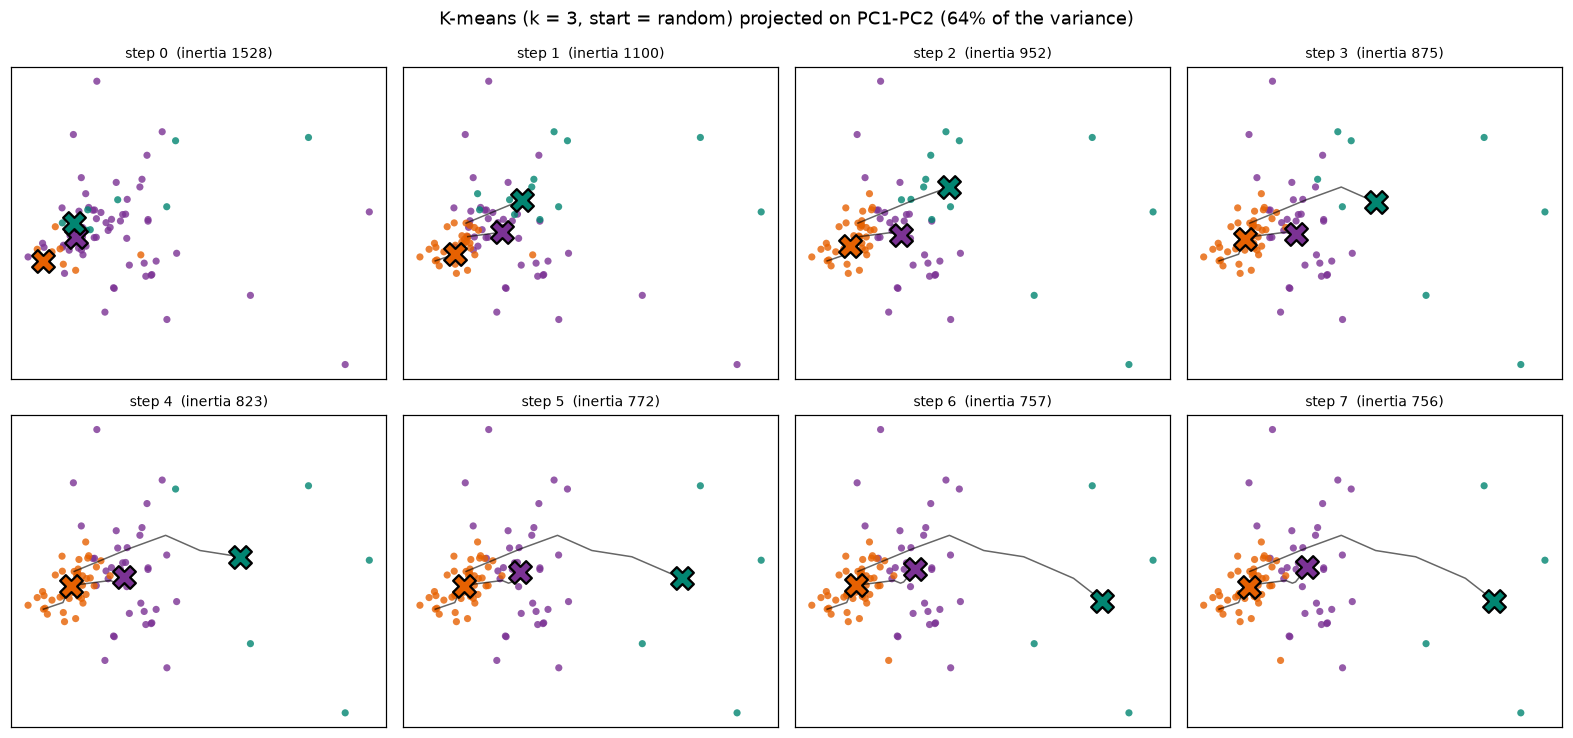

In [5]:
def draw_step(ax, i, title=True):
    h = history[i]
    C = proj(h["centres"])
    for j in range(K):
        m = h["labels"] == j
        ax.scatter(P[m, 0], P[m, 1], s=22, color=CLUSTER_COLORS[j], alpha=0.8, edgecolor="none")
        path = proj(np.array([history[t]["centres"][j] for t in range(i + 1)]))
        ax.plot(path[:, 0], path[:, 1], "-", color="k", lw=1, alpha=0.6)
        ax.scatter(C[j, 0], C[j, 1], marker="X", s=220, color=CLUSTER_COLORS[j],
                   edgecolor="k", linewidth=1.5, zorder=5)
    if title:
        ax.set_title(f"step {i}  (inertia {h['inertia']:.0f})", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])


n_show = min(len(history), 8)
steps = np.unique(np.linspace(0, len(history) - 1, n_show).round().astype(int))
ncol = 4
nrow = int(np.ceil(len(steps) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.6 * ncol, 3.4 * nrow), squeeze=False)
for ax, i in zip(axes.flat, steps):
    draw_step(ax, i)
for ax in axes.flat[len(steps):]:
    ax.axis("off")
fig.suptitle(f"K-means (k = {K}, start = {INIT}) projected on {pair_name} ({var2.sum():.0f}% of the variance)")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "01_kmeans_steps.png", dpi=200)
plt.show()

### 2b. The same as an animation
Press ▶ to play it. You can also go frame by frame with the buttons.

In [6]:
fig, ax = plt.subplots(figsize=(6, 5))

def update(i):
    ax.clear()
    draw_step(ax, i, title=False)
    ax.set_title(f"step {i} of {len(history) - 1}   inertia = {history[i]['inertia']:.0f}")
    ax.set_xlabel(xlab); ax.set_ylabel(ylab)

anim = animation.FuncAnimation(fig, update, frames=len(history), interval=900)
plt.close(fig)          # show only the animation, not an extra static figure
display(HTML(anim.to_jshtml()))

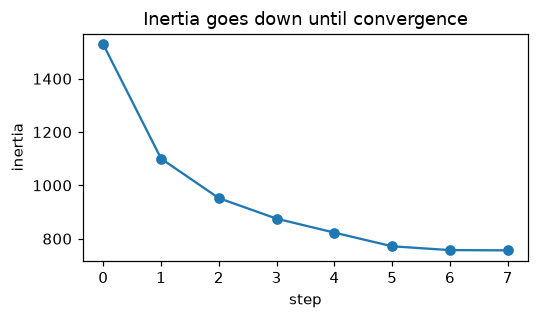

In [7]:
# Inertia at every step: it must always go down
fig, ax = plt.subplots(figsize=(5, 3))
ax.plot([h["inertia"] for h in history], "o-")
ax.set_xlabel("step"); ax.set_ylabel("inertia"); ax.set_title("Inertia goes down until convergence")
fig.tight_layout(); plt.show()

### 2c. Does the starting point matter?
K-means can end in different solutions depending on where the centres start. `sklearn` runs it many times (`n_init`) and keeps the run with the **lowest inertia**. Here we run our version with 10 different seeds and compare it with `sklearn`.

In [8]:
finals = []
for s in range(10):
    h = kmeans_with_history(X, K, init=INIT, seed=s, max_iter=MAX_ITER)
    finals.append((s, h[-1]["inertia"], len(h)))
print(pd.DataFrame(finals, columns=["seed", "final inertia", "steps"]).to_string(index=False))

km = KMeans(n_clusters=K, n_init=20, random_state=0).fit(X)
labels = km.labels_          # <- the clusters used from here on
print(f"\nsklearn best inertia: {km.inertia_:.1f}")
print(f"Same partition as our run with SEED={SEED}? "
      f"ARI = {adjusted_rand_score(labels, history[-1]['labels']):.2f} (1 = identical)")

 seed  final inertia  steps
    0     756.346638      8
    1     837.682445     17
    2     839.234716     11
    3     872.273264     11
    4     754.982368      5
    5     754.138414     16
    6     754.138414     16
    7     754.138414     10
    8     839.234716      8
    9     796.073016      3


c:\Users\natal\anaconda3\envs\niemannpick\Lib\site-packages\sklearn\cluster\_kmeans.py:1424: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(



sklearn best inertia: 753.2
Same partition as our run with SEED=0? ARI = 0.76 (1 = identical)


## 3. Do the clusters match the study groups?

- **Table:** how many sessions of each group fall in each cluster. If k-means had found the groups, each row would be mostly one group.
- **ARI (Adjusted Rand Index):** 1 = clusters identical to the groups, 0 = no better than random.
- We also check whether clusters follow **animals** or the **odd subgroup** instead of the groups.

In [9]:
print("Clusters vs GROUPS:")
display(pd.crosstab(pd.Series(labels, name="cluster"), pd.Series(groups, name="group"), margins=True))
print(f"ARI clusters vs groups: {adjusted_rand_score(groups, labels):.2f}")
print(f"Silhouette of the clusters: {silhouette_score(X, labels):.2f}")

print("\nClusters vs ANIMALS (sessions of each mouse in each cluster):")
display(pd.crosstab(pd.Series(animals, name="animal"), pd.Series(labels, name="cluster")))

if odd.any():
    print("Clusters vs ODD SUBGROUP:")
    display(pd.crosstab(pd.Series(labels, name="cluster"),
                        pd.Series(np.where(odd, "odd", "normal"), name="session")))

Clusters vs GROUPS:


group,EFV,NPC,WT,All
cluster,,,,
0,0,0,4,4
1,12,9,6,27
2,25,32,0,57
All,37,41,10,88


ARI clusters vs groups: 0.14
Silhouette of the clusters: 0.29

Clusters vs ANIMALS (sessions of each mouse in each cluster):


cluster,0,1,2
animal,,,
EFV_218,0,3,4
EFV_220,0,3,5
EFV_263,0,0,1
EFV_277,0,0,7
EFV_279,0,1,5
EFV_280,0,5,3
NPC_249,0,0,9
NPC_250,0,2,6
NPC_262,0,0,11


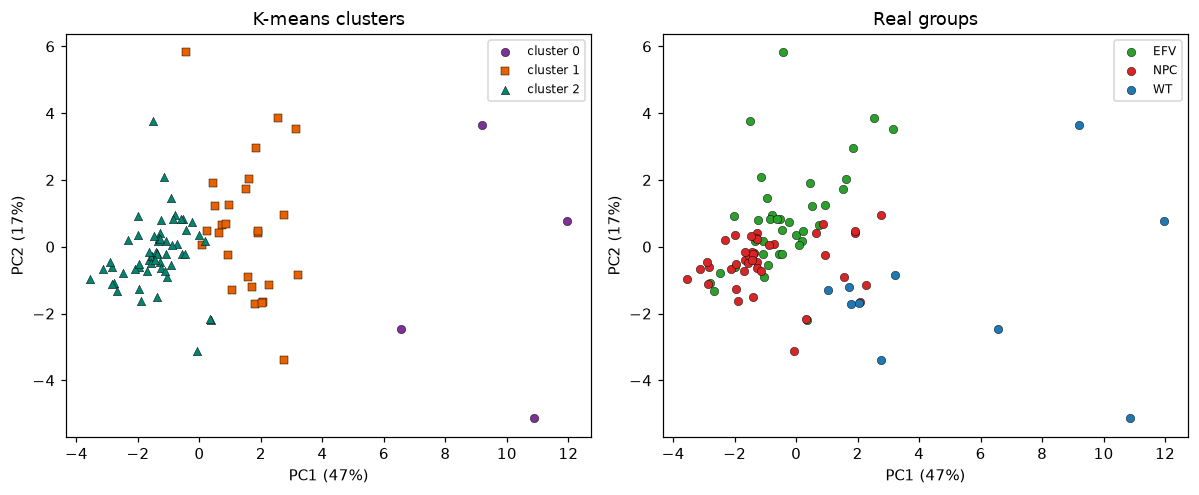

In [10]:
# Side by side: colored by k-means cluster vs colored by real group
fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for j in range(K):
    m = labels == j
    axes[0].scatter(P[m, 0], P[m, 1], s=30, color=CLUSTER_COLORS[j], marker=CLUSTER_MARKERS[j],
                    edgecolor="k", linewidth=0.3, label=f"cluster {j}")
for gi, g in enumerate(pd.unique(groups)):
    m = groups == g
    axes[1].scatter(P[m, 0], P[m, 1], s=30, color=cfg.color_for(g, gi), edgecolor="k",
                    linewidth=0.3, label=g)
for ax in axes:
    if odd.any():
        ax.scatter(P[odd, 0], P[odd, 1], s=110, facecolor="none", edgecolor="k", lw=1.2,
                   label="odd subgroup")
    ax.set_xlabel(xlab); ax.set_ylabel(ylab)
    ax.legend(fontsize=8)
axes[0].set_title("K-means clusters"); axes[1].set_title("Real groups")
fig.tight_layout(); fig.savefig(OUTPUT_DIR / "02_clusters_vs_groups.png", dpi=200); plt.show()

### 3b. Every pair of principal components
One 2-D picture only shows two directions. Here are **all the pairs** of the first PCs (colored by k-means cluster). On the diagonal: how each cluster is distributed along that single PC. If the clusters overlap in one pair but separate in another, the separating information lives in those other PCs.

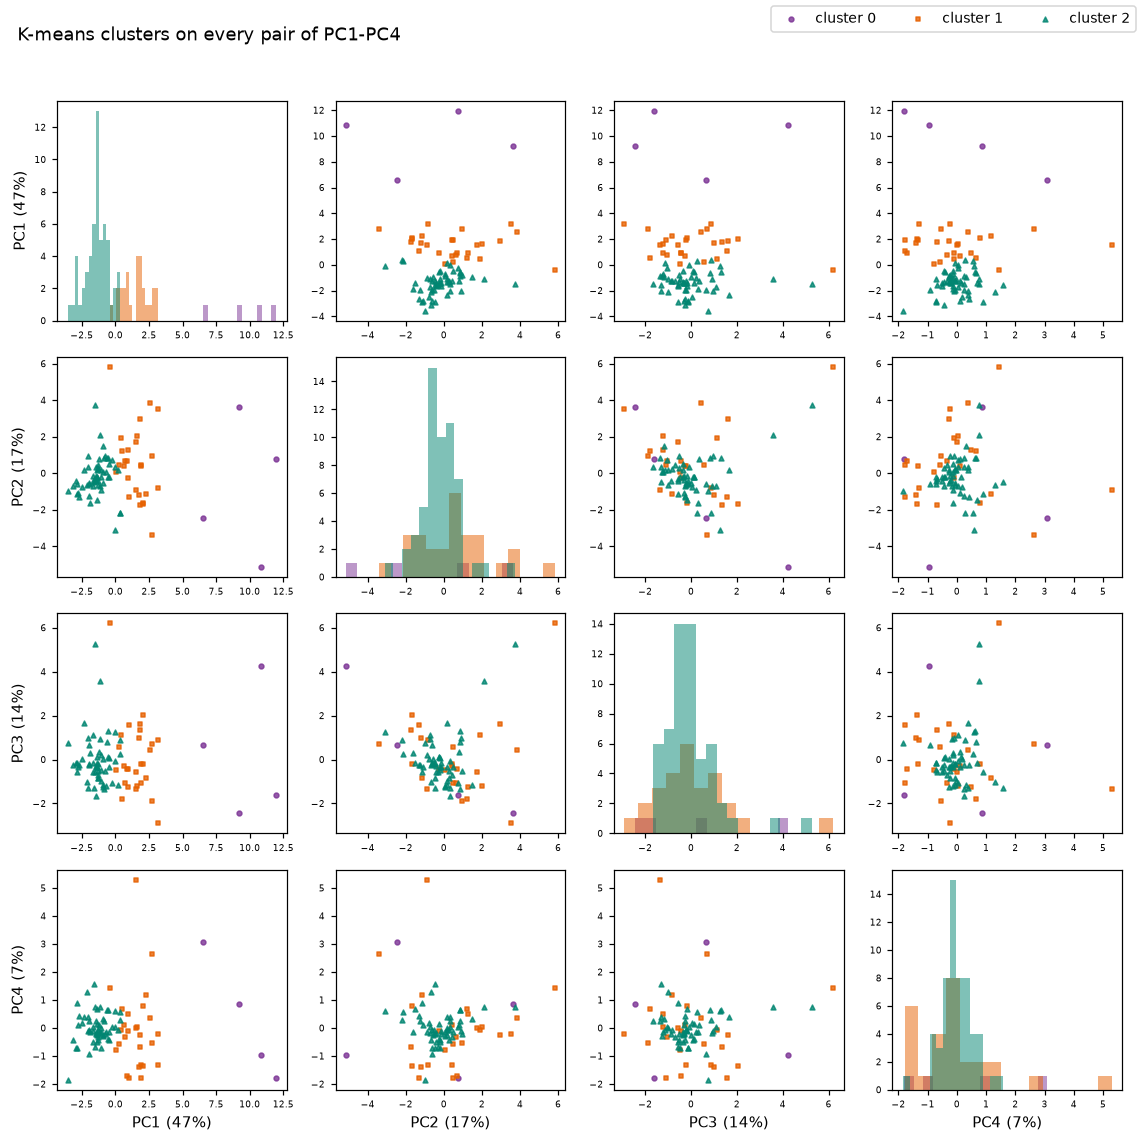

In [11]:
n = P_all.shape[1]
fig, axes = plt.subplots(n, n, figsize=(2.6 * n, 2.6 * n), squeeze=False)
for i in range(n):
    for j in range(n):
        ax = axes[i, j]
        for c in range(K):
            m = labels == c
            if i == j:
                ax.hist(P_all[m, i], bins=15, alpha=0.5, color=CLUSTER_COLORS[c])
            else:
                ax.scatter(P_all[m, j], P_all[m, i], s=10, color=CLUSTER_COLORS[c],
                           marker=CLUSTER_MARKERS[c], alpha=0.8,
                           label=f"cluster {c}" if (i, j) == (0, 1) else None)
        if i == n - 1:
            ax.set_xlabel(f"PC{j + 1} ({var_all[j]:.0f}%)")
        if j == 0:
            ax.set_ylabel(f"PC{i + 1} ({var_all[i]:.0f}%)")
        ax.tick_params(labelsize=6)
fig.legend(loc="upper right", ncol=K, fontsize=9)
fig.suptitle(f"K-means clusters on every pair of PC1-PC{n}", x=0.02, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(OUTPUT_DIR / "02b_clusters_all_pc_pairs.png", dpi=200)
plt.show()

## 4. Looking at the data through the feature values

Two views. All values are **z-scores**: 0 = average session, **red = higher** than average, **blue = lower** (in standard deviations).

### 4a. Cluster profiles (the easiest to read)
One row per cluster, one column per feature: the **average z-score** of the sessions in that cluster. A strong red or blue cell is a feature that characterizes that cluster. Below it, the same for the real groups, for comparison.

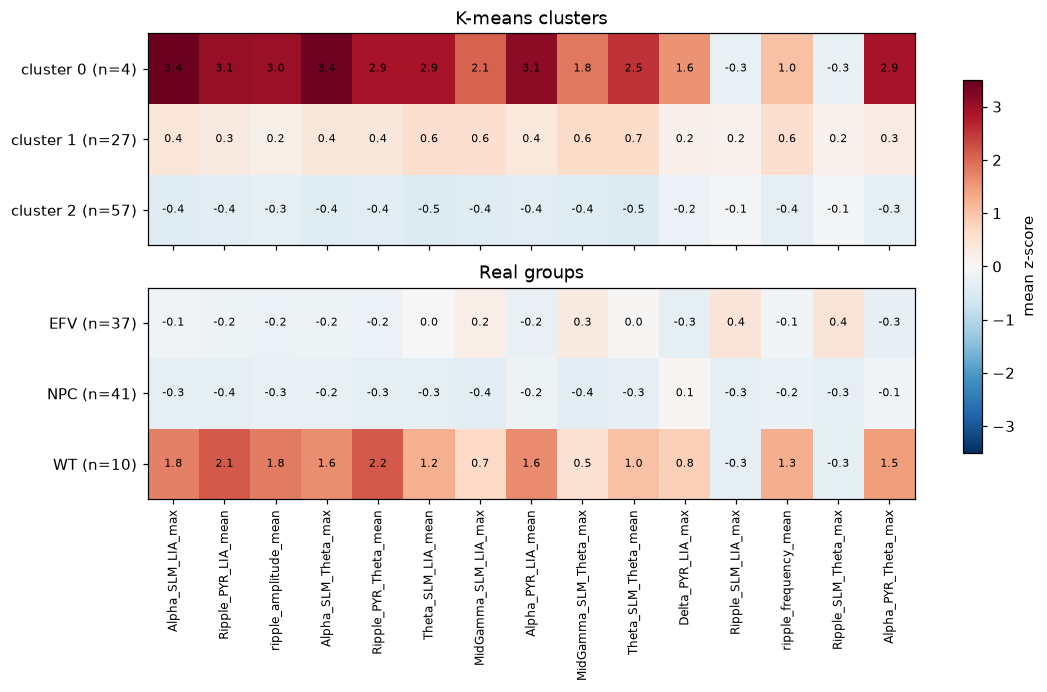

In [12]:
Z = pd.DataFrame(X, columns=feature_names)
prof_cluster = Z.groupby(labels).mean()
prof_cluster.index = [f"cluster {j} (n={np.sum(labels == j)})" for j in prof_cluster.index]
prof_group = Z.groupby(groups).mean()
prof_group.index = [f"{g} (n={np.sum(groups == g)})" for g in prof_group.index]

lim = max(1.0, np.ceil(max(prof_cluster.abs().max().max(), prof_group.abs().max().max()) * 2) / 2)
fig, axes = plt.subplots(2, 1, figsize=(0.55 * len(feature_names) + 3, 5.5),
                         gridspec_kw={"height_ratios": [K, len(prof_group)]})
for ax, prof, title in [(axes[0], prof_cluster, "K-means clusters"), (axes[1], prof_group, "Real groups")]:
    im = ax.imshow(prof.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_yticks(range(len(prof)), prof.index)
    ax.set_xticks(range(len(feature_names)), feature_names if ax is axes[1] else [], rotation=90, fontsize=8)
    if prof.shape[1] <= 30:          # numbers only when they fit
        for r in range(prof.shape[0]):
            for c in range(prof.shape[1]):
                ax.text(c, r, f"{prof.values[r, c]:.1f}", ha="center", va="center", fontsize=7)
    ax.set_title(title)
fig.colorbar(im, ax=axes, label="mean z-score", shrink=0.8)
fig.savefig(OUTPUT_DIR / "03_profiles.png", dpi=200, bbox_inches="tight"); plt.show()

### 4b. The PCA picture colored by each feature
One small panel per feature: the same 2-D picture (the pair `PC_X`-`PC_Y` from the settings), but each session is colored by **its value of that feature**. Marker shape = k-means cluster. A feature whose colors change smoothly along the cloud is one that "drives" that direction; if red and blue are mixed everywhere, that feature does not shape the clusters.

You have many features, so you can show only some of them with `FEATURE_FILTER` in the settings (e.g. `"CSD"`, `"Theta"`, `"SLM"`, `"ripple"`).

Showing 15 of 15 features


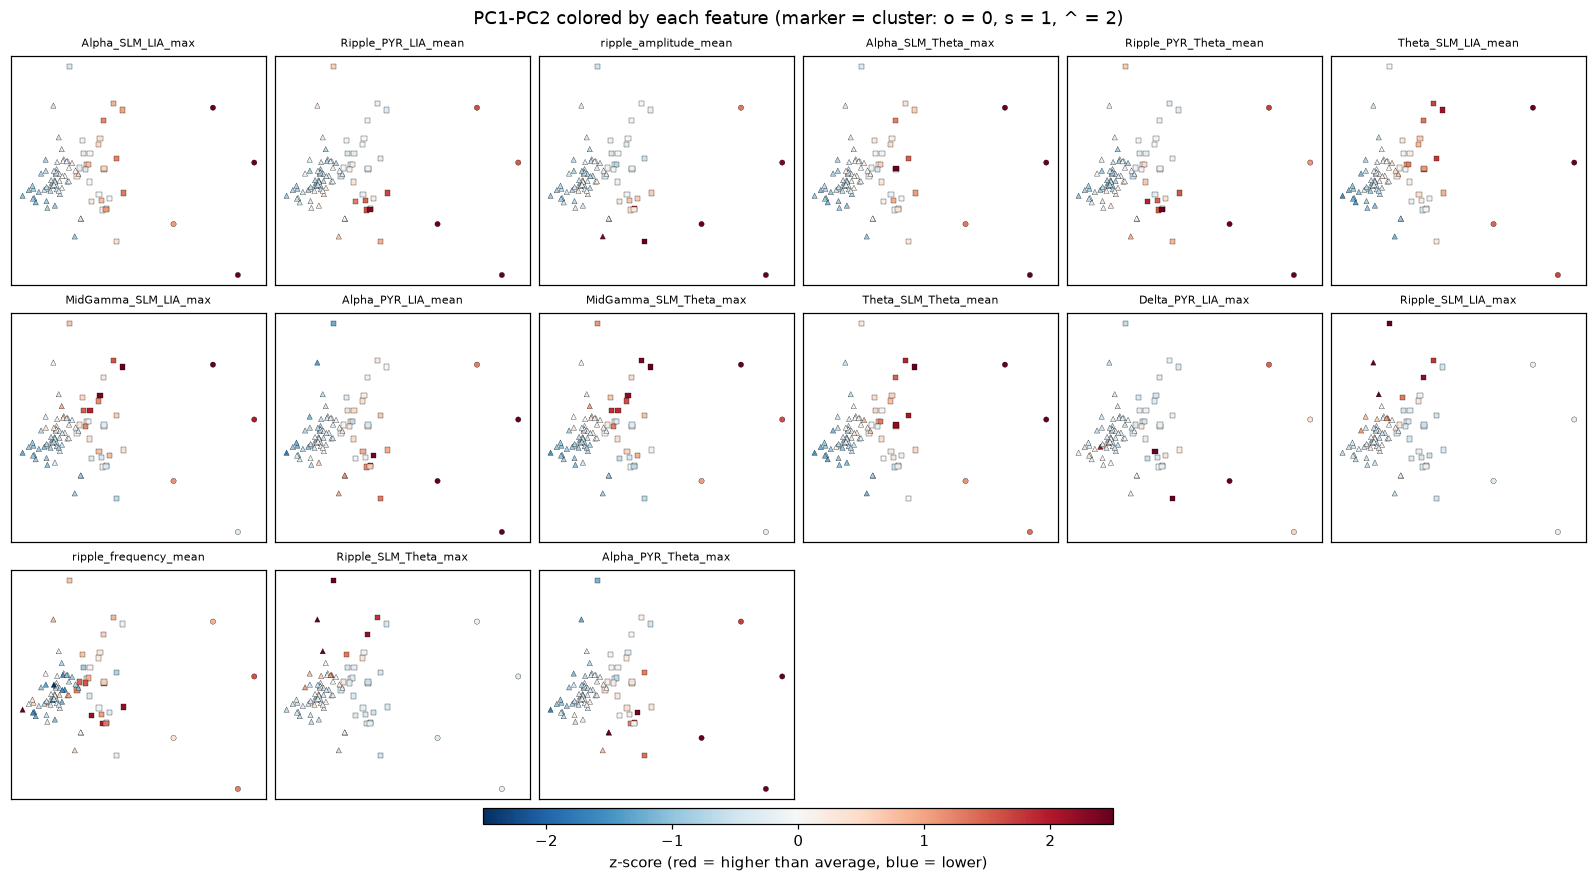

In [13]:
show = [f for f in feature_names if FEATURE_FILTER is None or FEATURE_FILTER.lower() in f.lower()]
print(f"Showing {len(show)} of {len(feature_names)} features")
ncol = min(6, len(show))
nrow = int(np.ceil(len(show) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(2.4 * ncol, 2.3 * nrow + 1.0), squeeze=False,
                         layout="constrained")
for n, f in enumerate(show):
    ax = axes.flat[n]
    col = feature_names.index(f)
    for j in range(K):
        m = labels == j
        sc = ax.scatter(P[m, 0], P[m, 1], c=np.clip(X[m, col], -2.5, 2.5), cmap="RdBu_r",
                        vmin=-2.5, vmax=2.5, s=12, marker=CLUSTER_MARKERS[j],
                        edgecolor="k", linewidth=0.2)
    ax.set_title(f, fontsize=7); ax.set_xticks([]); ax.set_yticks([])
for ax in axes.flat[len(show):]:
    ax.axis("off")
fig.colorbar(sc, ax=axes, location="bottom", shrink=0.4, aspect=40, pad=0.01,
             label="z-score (red = higher than average, blue = lower)")
fig.suptitle(f"{pair_name} colored by each feature (marker = cluster: " +
             ", ".join(f"{CLUSTER_MARKERS[j]} = {j}" for j in range(K)) + ")")
fig.savefig(OUTPUT_DIR / "05_pca_by_feature.png", dpi=200, bbox_inches="tight"); plt.show()

## 5. Save the cluster of every session

In [14]:
out = ids.copy()
out["cluster"] = labels
out["odd_subgroup"] = odd
for i in range(P_all.shape[1]):
    out[f"PC{i + 1}"] = P_all[:, i]
with pd.ExcelWriter(OUTPUT_DIR / "kmeans_results.xlsx") as w:
    out.to_excel(w, sheet_name="sessions", index=False)
    prof_cluster.to_excel(w, sheet_name="cluster_profiles")
    prof_group.to_excel(w, sheet_name="group_profiles")
print(f"Saved in {OUTPUT_DIR}")

Saved in D:\Violeta\ANALISIS\RESULTSNatalia\kmeans_results_selected\all
